# 01 — dunnhumby EDA: first look & data quality

**Goal:** understand the 7 dunnhumby tables before any cleaning or modeling.
Every number written in `docs/data_quality_report.md` comes from a cell in this notebook.

Reference: `data/raw/dunnhumby/dunnhumby_user_guide.pdf` (2023 edition, official download).

## 1. Setup and loading

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Works whether Jupyter was started from the project root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = ROOT / "data" / "raw" / "dunnhumby"

for f in sorted(RAW.glob("*.csv")):
    print(f"{f.name:<25} {f.stat().st_size / 1024**2:>8.1f} MB on disk")

campaign_desc.csv              0.0 MB on disk
campaign_table.csv             0.1 MB on disk
coupon.csv                     2.7 MB on disk
coupon_redempt.csv             0.1 MB on disk
hh_demographic.csv             0.0 MB on disk
product.csv                    6.1 MB on disk
transaction_data.csv         135.2 MB on disk


In [2]:
tables = {f.stem: pd.read_csv(f) for f in sorted(RAW.glob("*.csv"))}

overview = pd.DataFrame({
    name: {"rows": len(df), "columns": df.shape[1],
           "memory_MB": round(df.memory_usage(deep=True).sum() / 1024**2, 1),
           "null_cells": int(df.isna().sum().sum()),
           "duplicate_rows": int(df.duplicated().sum())}
    for name, df in tables.items()
}).T
overview

,rows,columns,memory_MB,null_cells,duplicate_rows
campaign_desc,30.0,4.0,0.0,0.0,0.0
campaign_table,7208.0,3.0,0.2,0.0,0.0
coupon,124548.0,3.0,2.9,0.0,5164.0
coupon_redempt,2318.0,4.0,0.1,0.0,0.0
hh_demographic,801.0,8.0,0.1,0.0,0.0
product,92353.0,7.0,9.5,0.0,0.0
transaction_data,2595732.0,12.0,237.6,0.0,0.0


`memory_usage(deep=True)` counts the real size of text columns; without `deep=True` pandas only counts the 8-byte pointers.

In [3]:
tx = tables["transaction_data"]
product = tables["product"]
demo = tables["hh_demographic"]
camp_desc = tables["campaign_desc"]
camp_hh = tables["campaign_table"]
coupon = tables["coupon"]
redempt = tables["coupon_redempt"]

for name, df in tables.items():
    print(f"--- {name}")
    print(df.dtypes.to_string(), "\n")

--- campaign_desc
DESCRIPTION      str
CAMPAIGN       int64
START_DAY      int64
END_DAY        int64 

--- campaign_table
DESCRIPTION        str
household_key    int64
CAMPAIGN         int64 

--- coupon
COUPON_UPC    int64
PRODUCT_ID    int64
CAMPAIGN      int64 

--- coupon_redempt
household_key    int64
DAY              int64
COUPON_UPC       int64
CAMPAIGN         int64 

--- hh_demographic
classification_1       str
classification_2       str
classification_3       str
HOMEOWNER_DESC         str
classification_5       str
classification_4       str
KID_CATEGORY_DESC      str
household_key        int64 

--- product
PRODUCT_ID              int64
MANUFACTURER            int64
DEPARTMENT                str
BRAND                     str
COMMODITY_DESC            str
SUB_COMMODITY_DESC        str
CURR_SIZE_OF_PRODUCT      str 

--- transaction_data
household_key          int64
BASKET_ID              int64
DAY                    int64
PRODUCT_ID             int64
QUANTITY              

## 2. Keys and referential integrity

In [4]:
checks = {
    "transaction households": tx.household_key.nunique(),
    "baskets": tx.BASKET_ID.nunique(),
    "products bought": tx.PRODUCT_ID.nunique(),
    "products in catalogue": product.PRODUCT_ID.nunique(),
    "PRODUCT_ID unique in product.csv": product.PRODUCT_ID.is_unique,
    "transaction products missing from product.csv": int((~tx.PRODUCT_ID.isin(product.PRODUCT_ID)).sum()),
    "stores": tx.STORE_ID.nunique(),
    "baskets spanning >1 household": int((tx.groupby("BASKET_ID").household_key.nunique() > 1).sum()),
    "baskets spanning >1 day": int((tx.groupby("BASKET_ID").DAY.nunique() > 1).sum()),
    "demographic households found in transactions": int(demo.household_key.isin(tx.household_key).sum()),
    "campaign households found in transactions": int(camp_hh.household_key.drop_duplicates().isin(tx.household_key).sum()),
    "coupon.csv duplicate rows": int(coupon.duplicated().sum()),
}
pd.Series(checks, name="value").to_frame()

,value
transaction households,2500
baskets,276484
products bought,92339
products in catalogue,92353
PRODUCT_ID unique in product.csv,True
transaction products missing from product.csv,0
stores,582
baskets spanning >1 household,0
baskets spanning >1 day,0
demographic households found in transactions,801


## 3. Time coverage (A01)

DAY range: 1 - 711
WEEK_NO range: 1 - 102
TRANS_TIME range: 0 - 2359 (HHMM as integer)


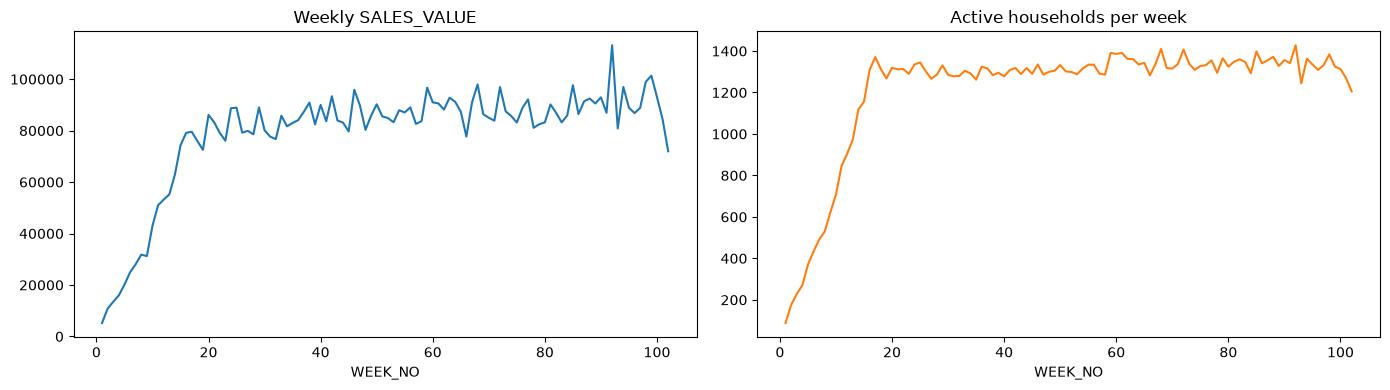

In [5]:
print("DAY range:", tx.DAY.min(), "-", tx.DAY.max())
print("WEEK_NO range:", tx.WEEK_NO.min(), "-", tx.WEEK_NO.max())
print("TRANS_TIME range:", tx.TRANS_TIME.min(), "-", tx.TRANS_TIME.max(), "(HHMM as integer)")

weekly = tx.groupby("WEEK_NO").agg(sales=("SALES_VALUE", "sum"), households=("household_key", "nunique"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
weekly.sales.plot(ax=ax[0], title="Weekly SALES_VALUE")
weekly.households.plot(ax=ax[1], title="Active households per week", color="tab:orange")
plt.tight_layout(); plt.show()

Watch the first weeks: if activity ramps up, households were being added over time. That matters for tenure features and for choosing a training window.

## 4. Quantity and sales anomalies

In [6]:
anomalies = {
    "QUANTITY == 0": int((tx.QUANTITY == 0).sum()),
    "SALES_VALUE == 0": int((tx.SALES_VALUE == 0).sum()),
    "SALES_VALUE < 0": int((tx.SALES_VALUE < 0).sum()),
    "QUANTITY == 0 and SALES_VALUE == 0": int(((tx.QUANTITY == 0) & (tx.SALES_VALUE == 0)).sum()),
    "QUANTITY == 0 but SALES_VALUE > 0": int(((tx.QUANTITY == 0) & (tx.SALES_VALUE > 0)).sum()),
    "QUANTITY > 100": int((tx.QUANTITY > 100).sum()),
}
pd.Series(anomalies, name="rows").to_frame()

,rows
QUANTITY == 0,14466
SALES_VALUE == 0,18850
SALES_VALUE < 0,0
QUANTITY == 0 and SALES_VALUE == 0,14399
QUANTITY == 0 but SALES_VALUE > 0,67
QUANTITY > 100,23136


In [7]:
# Which products carry the huge quantities?
big = tx[tx.QUANTITY > 100].merge(product, on="PRODUCT_ID", how="left")
big.groupby(["DEPARTMENT", "COMMODITY_DESC"]).agg(rows=("QUANTITY", "size"),
                                                  median_qty=("QUANTITY", "median"),
                                                  max_qty=("QUANTITY", "max")).sort_values("rows", ascending=False).head(10)

,,rows,median_qty,max_qty
DEPARTMENT,COMMODITY_DESC,,,
KIOSK-GAS,COUPON/MISC ITEMS,20261,10551.0,89638
MISC SALES TRAN,COUPON/MISC ITEMS,2868,12504.5,85055
KIOSK-GAS,FUEL,6,18777.5,30080
PRODUCE,CORN,1,144.0,144


## 5. Discounts and the guide's price formulas (A02, A03)

In [8]:
for c in ["RETAIL_DISC", "COUPON_DISC", "COUPON_MATCH_DISC"]:
    print(f"{c:<18} nonzero rows: {(tx[c] != 0).sum():>9,}   positive rows: {(tx[c] > 0).sum():>3}")

RETAIL_DISC        nonzero rows: 1,303,062   positive rows:  36
COUPON_DISC        nonzero rows:    36,422   positive rows:   0
COUPON_MATCH_DISC  nonzero rows:    17,449   positive rows:   0


In [9]:
# Reproduce the guide's three example lines (guide p.3) from the real data
example = tx[tx.BASKET_ID.isin([35730137393, 41756231898, 36027750817]) & (tx.PRODUCT_ID == 819063)].copy()
q = example.QUANTITY
example["guide_loyalty_formula"] = (example.SALES_VALUE - (example.RETAIL_DISC + example.COUPON_MATCH_DISC)) / q
example["guide_non_loyalty_formula"] = (example.SALES_VALUE - example.COUPON_MATCH_DISC) / q
example["customer_paid"] = example.SALES_VALUE + example.COUPON_DISC
example[["household_key", "BASKET_ID", "QUANTITY", "SALES_VALUE", "RETAIL_DISC", "COUPON_DISC",
         "COUPON_MATCH_DISC", "guide_loyalty_formula", "guide_non_loyalty_formula", "customer_paid"]]

,household_key,BASKET_ID,QUANTITY,SALES_VALUE,RETAIL_DISC,COUPON_DISC,COUPON_MATCH_DISC,guide_loyalty_formula,guide_non_loyalty_formula,customer_paid
1871405,2381,35730137393,1,1.67,0.00,0.00,0.00,1.67,1.67,1.67
1899784,888,36027750817,2,2.89,0.00,-0.55,-0.45,1.67,1.67,2.34
2422124,1431,41756231898,2,2.00,-1.34,0.00,0.00,1.67,1.00,2.00


**Reading the result (guide Line 2: SALES_VALUE 2.00, RETAIL_DISC -1.34, QUANTITY 2):**
the formula the guide labels *loyalty card price* gives 1.67, which the guide's own text calls the
"regular shelf price (exclusive of loyalty card discount)". The *non-loyalty* formula gives 1.00, which the
text calls the "shelf price including loyalty card discount". The formulas are printed as-is in the docs; the
labels contradict the guide's own example, so in code they are named `shelf_price` and `card_price`.

In [10]:
valid = tx[tx.QUANTITY > 0]
shelf_price = (valid.SALES_VALUE - (valid.RETAIL_DISC + valid.COUPON_MATCH_DISC)) / valid.QUANTITY
card_price = (valid.SALES_VALUE - valid.COUPON_MATCH_DISC) / valid.QUANTITY
print(f"shelf_price >= card_price on {(shelf_price >= card_price - 1e-9).mean():.5%} of rows")
print(f"rows where it fails: {(shelf_price < card_price - 1e-9).sum()} (all with positive RETAIL_DISC?)",
      ((shelf_price < card_price - 1e-9) & (valid.RETAIL_DISC > 0)).sum())

totals = pd.Series({
    "SALES_VALUE (retailer received)": tx.SALES_VALUE.sum(),
    "customer paid (SALES_VALUE + COUPON_DISC)": (tx.SALES_VALUE + tx.COUPON_DISC).sum(),
    "loyalty discounts (RETAIL_DISC)": tx.RETAIL_DISC.sum(),
    "manufacturer coupons (COUPON_DISC)": tx.COUPON_DISC.sum(),
    "retailer coupon match (COUPON_MATCH_DISC)": tx.COUPON_MATCH_DISC.sum(),
}).round(2)
totals.to_frame("total $")

shelf_price >= card_price on 99.99992% of rows
rows where it fails: 2 (all with positive RETAIL_DISC?) 2


,total $
SALES_VALUE (retailer received),8057463.08
customer paid (SALES_VALUE + COUPON_DISC),8014851.54
loyalty discounts (RETAIL_DISC),-1398334.84
manufacturer coupons (COUPON_DISC),-42611.54
retailer coupon match (COUPON_MATCH_DISC),-7575.81


## 6. Households

In [11]:
hh = tx.groupby("household_key").agg(
    first_day=("DAY", "min"), last_day=("DAY", "max"),
    baskets=("BASKET_ID", "nunique"), active_weeks=("WEEK_NO", "nunique"),
    sales=("SALES_VALUE", "sum"))
hh["tenure_days"] = hh.last_day - hh.first_day
hh["avg_basket"] = hh.sales / hh.baskets
hh.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
first_day,2500.0,65.9,39.2,1.0,36.0,69.0,95.0,671.0
last_day,2500.0,685.4,62.8,54.0,691.0,705.0,710.0,711.0
baskets,2500.0,110.6,115.7,1.0,39.0,79.0,142.2,1300.0
active_weeks,2500.0,49.6,25.5,1.0,28.0,50.0,71.0,102.0
sales,2500.0,3223.0,3349.0,8.2,970.7,2157.8,4413.3,38319.8
tenure_days,2500.0,619.5,74.1,0.0,599.0,626.0,661.0,710.0
avg_basket,2500.0,31.6,19.1,2.4,18.3,27.4,40.5,165.8


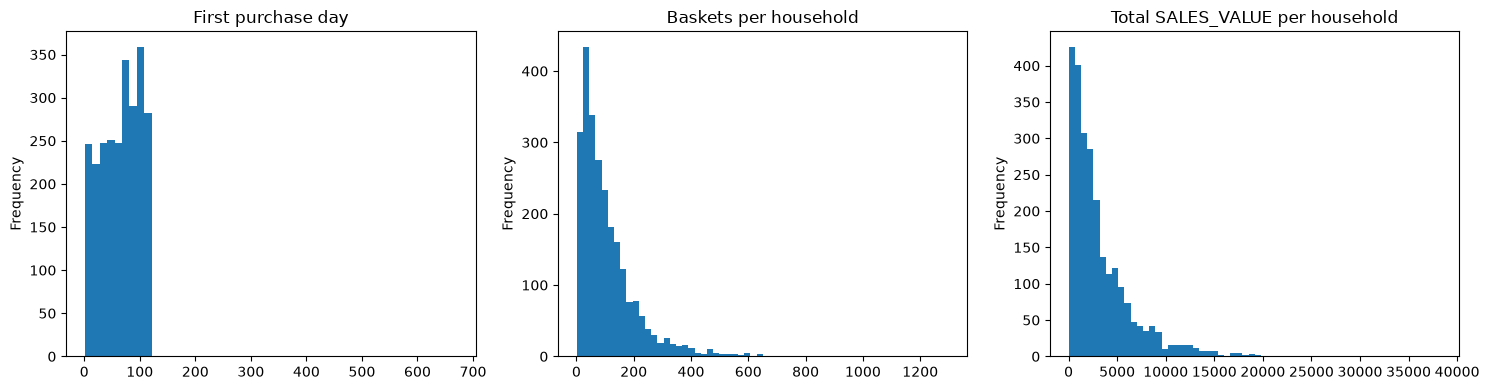

Top 10% of households = 34.3% of sales


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
hh.first_day.plot.hist(bins=50, ax=ax[0], title="First purchase day")
hh.baskets.plot.hist(bins=60, ax=ax[1], title="Baskets per household")
hh.sales.plot.hist(bins=60, ax=ax[2], title="Total SALES_VALUE per household")
plt.tight_layout(); plt.show()

top10_share = hh.sales.nlargest(int(len(hh) * 0.1)).sum() / hh.sales.sum()
print(f"Top 10% of households = {top10_share:.1%} of sales")

## 7. Products

In [13]:
dept = tx.merge(product[["PRODUCT_ID", "DEPARTMENT", "BRAND"]], on="PRODUCT_ID").groupby("DEPARTMENT").SALES_VALUE.sum()
(dept.sort_values(ascending=False) / dept.sum()).head(12).round(3).to_frame("share of sales")

,share of sales
DEPARTMENT,
GROCERY,0.508
DRUG GM,0.131
PRODUCE,0.069
MEAT,0.068
KIOSK-GAS,0.068
MEAT-PCKGD,0.051
DELI,0.032
PASTRY,0.015
MISC SALES TRAN,0.015


In [14]:
brand = tx.merge(product[["PRODUCT_ID", "BRAND"]], on="PRODUCT_ID").groupby("BRAND").SALES_VALUE.sum()
(brand / brand.sum()).round(3).to_frame("share of sales")

,share of sales
BRAND,
National,0.722
Private,0.278


## 8. Demographics (A04, A10)

In [15]:
print(f"Households with demographics: {len(demo)} of {tx.household_key.nunique()} ({len(demo)/tx.household_key.nunique():.1%})")
for c in demo.columns.drop("household_key"):
    print(f"{c:<18}", demo[c].value_counts().sort_index().to_dict())

Households with demographics: 801 of 2500 (32.0%)
classification_1   {'Age Group1': 46, 'Age Group2': 142, 'Age Group3': 194, 'Age Group4': 288, 'Age Group5': 59, 'Age Group6': 72}
classification_2   {'X': 340, 'Y': 344, 'Z': 117}
classification_3   {'Level1': 61, 'Level10': 11, 'Level11': 5, 'Level12': 11, 'Level2': 74, 'Level3': 77, 'Level4': 172, 'Level5': 192, 'Level6': 96, 'Level7': 34, 'Level8': 38, 'Level9': 30}
HOMEOWNER_DESC     {'Homeowner': 504, 'Probable Owner': 11, 'Probable Renter': 11, 'Renter': 42, 'Unknown': 233}
classification_5   {'Group1': 47, 'Group2': 95, 'Group3': 144, 'Group4': 187, 'Group5': 255, 'Group6': 73}
classification_4   {'1': 255, '2': 318, '3': 109, '4': 53, '5+': 66}
KID_CATEGORY_DESC  {'1': 114, '2': 60, '3+': 69, 'None/Unknown': 558}


**Value sets vs the 2023 guide.** The guide's demographic table lists these value sets: Group1–6, X/Y/Z, Level1–12, 1–5+,
Group1–6, Group1–5, and 1/2/3/None-Unknown. Its variable-name column is a copy-paste of the transaction table, so the
column-to-meaning link can only come from the values themselves:

| Column | Values found | Guide value set | Meaning |
|---|---|---|---|
| classification_1 | Age Group1–6 | Group1–6, ordered | age band (the values say "Age Group") |
| classification_2 | X, Y, Z | X/Y/Z, order not stated | unknown — treat as nominal |
| classification_3 | Level1–12 | Level1–12, ordered | unknown band — ordered |
| classification_4 | 1–5+ | 1 through 5+, ordered | count-like band — ordered |
| classification_5 | Group1–6 | Group1–6, ordered | unknown band — ordered |
| HOMEOWNER_DESC | readable | not in the 2023 table | homeowner status (not masked) |
| KID_CATEGORY_DESC | None/Unknown, 1, 2, 3+ | 1, 2, 3, None/Unknown | readable as is |

No meaning is assigned beyond what the values themselves show (A10).

In [16]:
# Representativeness: households with vs without demographics (standardized mean difference)
hh["has_demo"] = hh.index.isin(demo.household_key)
features = ["baskets", "sales", "avg_basket", "active_weeks", "tenure_days", "last_day"]
rows = []
for f in features:
    a, b = hh.loc[hh.has_demo, f], hh.loc[~hh.has_demo, f]
    smd = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    rows.append({"feature": f, "with_demo_median": a.median(), "without_demo_median": b.median(), "SMD": round(smd, 3)})
smd_table = pd.DataFrame(rows).set_index("feature")
smd_table

,with_demo_median,without_demo_median,SMD
feature,,,
baskets,139.000000,52.000,0.836
sales,4676.430000,1396.930,1.114
avg_basket,32.297009,25.311,0.403
active_weeks,73.000000,36.000,1.543
tenure_days,635.000000,621.000,0.418
last_day,709.000000,702.000,0.498


Rule of thumb: |SMD| > 0.1 is a meaningful difference. Large values mean the demographic subset is **not** a random
slice of the 2,500 households, and Model B results only describe that subset.

## 9. Campaigns and coupons

In [17]:
camp = camp_desc.assign(length=camp_desc.END_DAY - camp_desc.START_DAY)
reach = camp_hh.groupby("CAMPAIGN").household_key.nunique().rename("households_reached")
redeem = redempt.groupby("CAMPAIGN").household_key.nunique().rename("households_redeemed")
camp = camp.set_index("CAMPAIGN").join(reach).join(redeem).fillna({"households_redeemed": 0})
camp["redemption_rate"] = (camp.households_redeemed / camp.households_reached).round(3)
camp.sort_values("START_DAY")

,DESCRIPTION,START_DAY,END_DAY,length,households_reached,households_redeemed,redemption_rate
CAMPAIGN,,,,,,,
26,TypeA,224,264,40,332,31,0.093
27,TypeC,237,300,63,12,1,0.083
28,TypeB,259,320,61,17,1,0.059
29,TypeB,281,334,53,118,13,0.110
30,TypeA,323,369,46,361,36,0.100
1,TypeB,346,383,37,13,1,0.077
2,TypeB,351,383,32,48,2,0.042
3,TypeC,356,412,56,12,2,0.167
4,TypeB,372,404,32,81,6,0.074


In [18]:
print("Campaigns ending after the last transaction day (711):", camp.index[camp.END_DAY > 711].tolist())
print("Households reached by >= 1 campaign:", camp_hh.household_key.nunique())
print("Households that redeemed >= 1 coupon:", redempt.household_key.nunique())
print("Redemption rows:", len(redempt), "| distinct coupons redeemed:", redempt.COUPON_UPC.nunique())
camp.groupby("DESCRIPTION")[["households_reached", "households_redeemed"]].sum().assign(
    rate=lambda d: (d.households_redeemed / d.households_reached).round(3))

Campaigns ending after the last transaction day (711): [24]
Households reached by >= 1 campaign: 1584
Households that redeemed >= 1 coupon: 434
Redemption rows: 2318 | distinct coupons redeemed: 556


,households_reached,households_redeemed,rate
DESCRIPTION,,,
TypeA,3979,635,0.160
TypeB,2655,210,0.079
TypeC,574,44,0.077


## 10. Churn feasibility (A05)

Setup: pick a cutoff day; a household is *inactive* if it bought nothing in the `window` days after the cutoff.
Only households already active before the cutoff are counted, and `cutoff + window` must stay ≤ 711.

In [19]:
results = []
for cutoff in [500, 550, 600]:
    eligible = hh.index[hh.first_day <= cutoff]
    for window in [14, 30, 45, 60, 90]:
        if cutoff + window > tx.DAY.max():
            continue
        bought = tx.loc[(tx.DAY > cutoff) & (tx.DAY <= cutoff + window), "household_key"].unique()
        inactive = ~eligible.isin(bought)
        results.append({"cutoff": cutoff, "window_days": window, "eligible": len(eligible),
                        "inactive": int(inactive.sum()), "inactive_rate": round(inactive.mean(), 3)})
churn = pd.DataFrame(results).pivot(index="window_days", columns="cutoff", values="inactive_rate")
churn

cutoff,500,550,600
window_days,,,
14,0.318,0.310,0.301
30,0.190,0.185,0.178
45,0.141,0.128,0.130
60,0.109,0.099,0.101
90,0.077,0.072,0.071


In [20]:
# Permanent lapse: last purchase long before the end of the data
for gap in [60, 90, 120]:
    print(f"Households with no purchase in the last {gap} days: {(hh.last_day <= tx.DAY.max() - gap).mean():.1%}")

Households with no purchase in the last 60 days: 10.4%
Households with no purchase in the last 90 days: 7.0%
Households with no purchase in the last 120 days: 4.9%


## 11. Key findings

**Data is clean structurally.** No nulls, no duplicate transaction rows, every transaction product exists in
`product.csv`, each basket belongs to one household and one day. Only `coupon.csv` has duplicates (5,164 rows).

**Scale.** 2,595,732 transaction lines · 2,500 households · 276,484 baskets · 92,339 products · 582 stores ·
days 1–711 / weeks 1–102 (A01 confirmed).

**Households were onboarded over the first ~16 weeks.** Active households per week grow from 88 (week 1) to ~1,300
by week 16, then stay flat. 90.8% of households appear by week 16. Analyses of trends and time-windowed features
should start at week 17; earlier weeks understate activity.

**Fuel distorts quantities.** 23,136 lines have QUANTITY > 100, almost all `KIOSK-GAS` / `MISC SALES TRAN`
"COUPON/MISC ITEMS" (median ~10,000 units, max 89,638). KIOSK-GAS is also 6.8% of sales. These lines must be
excluded from basket-size/quantity features and handled explicitly in monetary features (A12).

**Zero lines.** 14,466 lines have QUANTITY = 0 (14,399 of them also SALES_VALUE = 0; 67 have sales > 0).

**Guide formulas reproduced on the real rows (A02, A03).** The guide's three example lines exist in the data and
give exactly 1.67 / 1.67 / 1.00 and customer-paid 2.34. The formula labeled "loyalty card price" yields the price
*without* the card. The shelf ≥ card price check holds on all but 2 rows (both with positive RETAIL_DISC, an
anomaly found on 36 rows in total).

**Money.** SALES_VALUE total $8,057,463; customer paid (SALES_VALUE + COUPON_DISC) $8,014,852; loyalty discounts
$1,398,335. Top 10% of households = 34.3% of sales. GROCERY is 50.8% of sales; national brands 72.2%.

**Demographics are not representative (A04).** 801 of 2,500 households (32.0%). Households with demographics
have far more baskets (median 139 vs 52) and sales (median $4,676 vs $1,397); SMD 0.84 for baskets, 1.11 for sales,
1.54 for active weeks — all far above 0.1. Any demographic model describes heavier shoppers only.

**Campaigns.** 30 campaigns reached 1,584 households; 434 redeemed at least one coupon (2,318 redemptions of 556
coupons). Household-level redemption rate: TypeA 16.0%, TypeB 7.9%, TypeC 7.7%. Campaign 24 ends on day 719,
after the last transaction day.

**Churn is not rare (A05).** With a cutoff at day 500–600, the share of households with no purchase in the next
window is ~31% (14 days), ~18% (30 days), ~10% (60 days), ~7% (90 days), stable across cutoffs. A 60-day window gives
a usable ~10% positive class without counting short breaks as churn. Spending decline (A06) is not needed as a fallback.